# Deep Generative Models: VAE and Diffusion on Fashion-MNIST

This notebook trains two generative models on Fashion-MNIST (28×28 grayscale images of clothing):

1. **Variational autoencoder (VAE)** with a 4-dimensional latent space, plus a visualization of what each latent direction encodes.
2. **Denoising diffusion probabilistic model (DDPM)**: forward noising, noise-prediction training, and ancestral sampling.

**Attribution.** This is my solution to Problem Set 5 of MIT 6.7960 *Deep Learning* (Fall 2024), which I took as self-study. The course specified the VAE architecture and provided parts of the training loops. The diffusion U-Net comes from the [`denoising-diffusion-pytorch`](https://github.com/lucidrains/denoising-diffusion-pytorch) library. I implemented the VAE (encoder, decoder, reparameterization), the ELBO loss, the latent-traversal plots, and the DDPM forward process, training step, and reverse sampler.

**To run:** Runtime → Change runtime type → GPU (T4), then Runtime → Run all. Total time is about 15 minutes.

## 0. Setup

In [ ]:
!pip install -q denoising_diffusion_pytorch

import os
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import FashionMNIST
from tqdm.auto import tqdm
from denoising_diffusion_pytorch import Unet

SEED = 1
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("assets", exist_ok=True)  # figures are saved here
print("Using device:", device)

Using device: cuda


## 1. Variational autoencoder

### 1.1 Model

The encoder maps an image $x$ to the mean and log-variance of a Gaussia distribution $q_\phi(z \mid x) = N(\mu, \sigma^2)$. A latent sample is drawn from this distribution with the reparameterization trick $z = \mu + \sigma \odot \varepsilon$ with $\varepsilon \sim N(0, I)$. The decoder maps $z$ back to pixel probabilities through $p_\theta (x\mid z)$. Both networks are MLPs on the flattened 784-pixel image.

In [ ]:
BATCH_SIZE = 128
train = FashionMNIST("./data", train=True, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True)


class VAE(nn.Module):
    def __init__(self, z_dims: int = 4, input_size: int = 784, num_hidden: int = 128):
        super().__init__()
        self.z_dims = z_dims
        self.encoder = nn.Sequential(
            nn.Linear(input_size, num_hidden), nn.ReLU(),
            nn.Linear(num_hidden, num_hidden), nn.ReLU(),
        )
        self.mu = nn.Linear(num_hidden, z_dims)       # mean of q(z|x)
        self.logvar = nn.Linear(num_hidden, z_dims)   # log-variance of q(z|x); more stable than predicting sigma
        self.decoder = nn.Sequential(
            nn.Linear(z_dims, num_hidden), nn.ReLU(),
            nn.Linear(num_hidden, num_hidden), nn.ReLU(),
            nn.Linear(num_hidden, input_size), nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor):
        # x: (B, 1, 28, 28) -> reshape (B, 784), mu (B, z), logvar (B, z)
        h = self.encoder(x.view(x.size(0), -1))
        mu, logvar = self.mu(h), self.logvar(h)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)   # reparameterization trick
        return self.decoder(z), mu, logvar

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 220kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.04MB/s]


### 1.2 Loss: the negative ELBO (evidence lower bound)

For each given input $x$, we want to maximize $p_\theta(x)$. Since $p_\theta(x)=\int p_\theta(x\mid z)p(z)dz$ is intractible. We want to instead maximize a lower bound on $\log p(x)$ called ELBO:
\begin{align*}
log p_\theta(x)&=\log \int q_\varphi(z\mid x)(p_\theta(x\mid z )(\frac{p(z)}{q_\varphi(z\mid x)})dz\\
&=\log \mathbb{E}_q[p_\theta(x\mid z)\frac{p(z)}{q_\varphi(z\mid x)}]\\
&\geq \mathbb{E}_q[\log p_\theta(x\mid z)\frac{p(z)}{q_\varphi(z\mid x)}]\text{ by Jensen's inequality}\\
&=\mathbb{E}_q[logp_\theta(x\mid z)]-D_{KL}(q_\varphi(z\mid x)\parallel p(z))
\end{align*}
Now we set the loss as negative ELBO
$$
L(x)=-\mathbb{E}_q[logp_\theta(x\mid z)]+D_{KL}(q_\varphi(z\mid x)\parallel p(z))
$$
The decoder gives $\hat{x}$, and we can take $p_\theta(x\mid z)=\prod_j \hat{x}_j^{x_j}(1-\hat{x}_j)^{1-x_j}$ as an approximation of the probability distribution (note that this would be the true probability if $x$ is binary, but good enough as approximation for $x$ gray-scale). Empirically,, the first term can be computed using binary cross entropy (BCE), even though the input data is not bindary.
\begin{align*}
BCE=\sum_{j}-x_jlog\hat{x}_j-(1-x_j)log(1-\hat{x}_j)
\end{align*}
and since a single sample $\hat{x}$ is an unbiased estimate of the expectation(average), during training it is sufficient to use that in the loss function. The second term can be computed using the following formula: the KL Divergence between two gaussians $q_1=N(\mu_1,\sigma_1)$ and $q_2=N(\mu_2,\sigma_2)$ is defined as follows:

  $$ D_{\text{KL}}(q_1 \parallel q_2) = log\Big(\frac{\sigma_2}{\sigma_1}\Big) + \frac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}-\frac{1}{2}$$

In [ ]:
def vae_loss(x_prime, x, mu, logvar):
    # negative ELBO, summed over the batch
    recon = F.binary_cross_entropy(x_prime, x.view(x.size(0), -1), reduction="sum") # compute -BCE from one sample, unbiased
    kl = 0.5 * torch.sum(torch.exp(logvar) + mu ** 2 - 1 - logvar)
    return recon + kl

### 1.3 Training (about 10 seconds per epoch)

In [ ]:
NUM_EPOCHS = 20
LR = 1e-3

vae_model = VAE().to(device)
optimizer = optim.Adam(vae_model.parameters(), lr=LR)

vae_history = []
for epoch in range(NUM_EPOCHS):
    vae_model.train()
    total = 0.0
    for X, _ in tqdm(train_loader, leave=False, desc=f"epoch {epoch}"):
        X = X.to(device)
        optimizer.zero_grad()
        x_prime, mu, logvar = vae_model(X)
        loss = vae_loss(x_prime, X, mu, logvar)
        loss.backward()
        optimizer.step()
        total += loss.item()
    vae_history.append(total / len(train_loader.dataset))
    print(f"Epoch {epoch:2d} | negative ELBO per image: {vae_history[-1]:.2f}")

epoch 0:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch  0 | negative ELBO per image: 301.67


epoch 1:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch  1 | negative ELBO per image: 258.10


epoch 2:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch  2 | negative ELBO per image: 253.21


... (30 outputs left out)

epoch 18:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 18 | negative ELBO per image: 244.57


epoch 19:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 19 | negative ELBO per image: 244.48


### 1.4 What does each latent dimension encode?

For each pair of latent dimensions $(i, j)$, we sweep $z_i, z_j$ over $[-3, 3]$, set every other coordinate to 0, and decode. Smooth transitions between clothes types show that the latent space is organized by meaningful features.

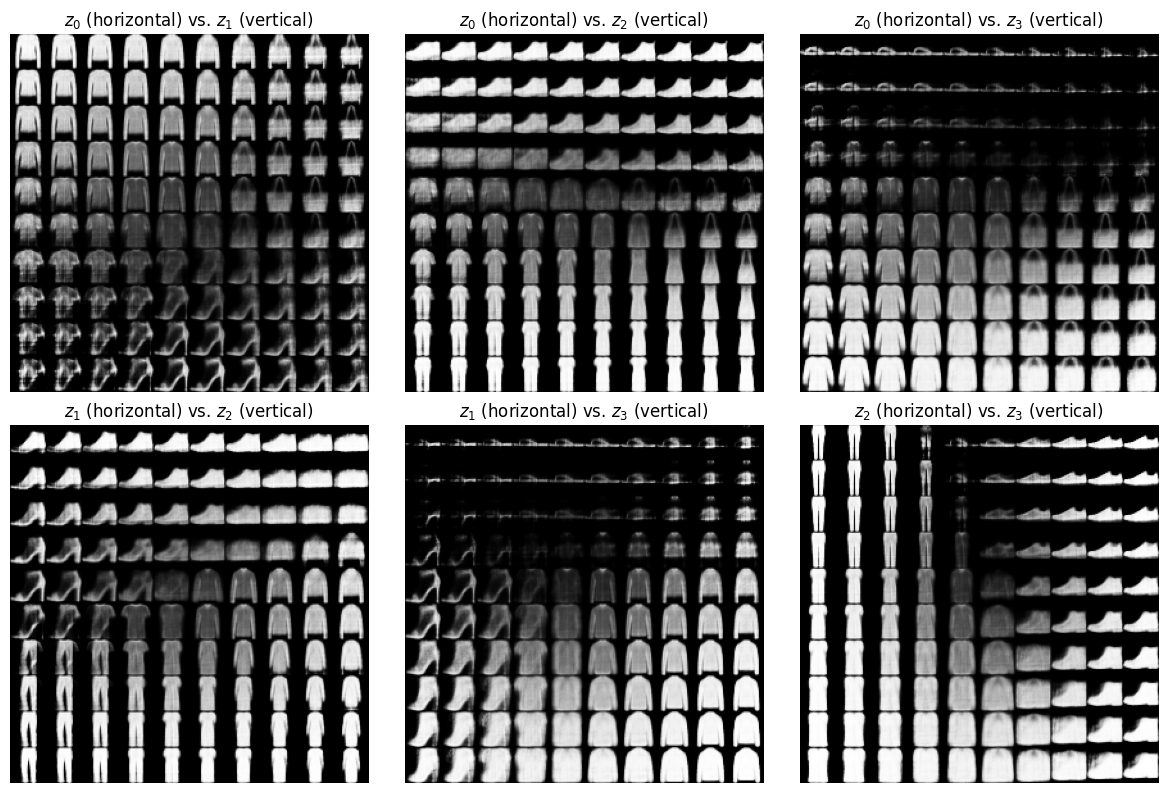

In [ ]:
@torch.no_grad()
def latent_grid(model, i: int, j: int, n: int = 10, lim: float = 3.0) -> np.ndarray:
    # decode an n x n sweep over latent dims (i, j) into one (28n, 28n) image
    values = torch.linspace(-3, 3, 10)
    canvas = np.zeros((280, 280))

    device = next(model.parameters()).device
    model.eval()

    with torch.no_grad():
        for row, y in enumerate(values.flip(0)):  # larger y-values at the top
            for col, x in enumerate(values):
                z = torch.zeros(1, model.z_dims, device=device)
                z[0, i] = x
                z[0, j] = y

                image = model.decoder(z).reshape(28, 28)
                image = image.cpu().numpy()

                canvas[row * 28:(row + 1) * 28,
                       col * 28:(col + 1) * 28] = image
    return canvas

# i, j encodes the coordinates of latent dimensions
pairs = [(i, j) for i in range(vae_model.z_dims) for j in range(i + 1, vae_model.z_dims)]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (i, j) in zip(axes.flat, pairs):
    ax.imshow(latent_grid(vae_model, i, j), cmap="gray")
    ax.set_title(f"$z_{i}$ (horizontal) vs. $z_{j}$ (vertical)")
    ax.axis("off")
plt.tight_layout()
plt.savefig("assets/vae_latent_traversals.png", dpi=120)
plt.show()

## 2. Denoising diffusion probabilistic models (DDPM)

Recall that a diffusion model works by first adding noise to the input image $x_0$ and then have a denoiser learn to gradually denoise an image in $T$ steps.

**Forward process.** With a variance schedule $\beta_1, \dots, \beta_T$, $\alpha_t = 1 - \beta_t$, and $\bar\alpha_t = \prod_{s \le t} \alpha_s$, noise can be added in closed form:
$$
x_t=\sqrt{a_t}x_{t-1}+\sqrt{1-\alpha_t}\epsilon, \qquad \varepsilon \sim N(0, I)
$$
which is equivalent to:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1 - \bar\alpha_t}\, \varepsilon, \qquad \varepsilon \sim N(0, I).$$

**Training.** A U-Net $\varepsilon_\theta(x_t, t)$ learns to predict the noise: $\;L= \mathbb{E}_{t, x_0, \varepsilon}\, \|\varepsilon - \varepsilon_\theta(x_t, t)\|^2$.

**Sampling.** Starting from $x_T \sim N(0, I)$, given the true $x_0$, we have $q(x_{t-1}\mid x_t, x_0)=N(\tilde{\mu}_t, \tilde{\beta}_t I)$, where
$$\tilde\mu_t = \frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\, x_t + \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,  x_0, \qquad \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\, \beta_t.$$

Note that each step estimates $\hat x_0 = \big(x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon_\theta\big)/\sqrt{\bar\alpha_t}$. We train the model to predict $p_\theta(x_{t-1}\mid x_t)=N(\mu_\theta(x_t, t), \tilde{\beta}_tI)$, where $\mu_\theta(x_t, t)=\tilde{\mu}_t(x_t, \hat{x}_0)$.
\begin{align*}
\mu_\theta(x_t,t)=\tilde{\mu}_t(x_t, \hat{x}_0)=\frac{1}{\sqrt{\alpha_t}}
(x_t-\frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}\epsilon_\theta(x_t,t))\end{align*}
and we sample from this posterior. For the loss function, want to minimize the following during our training:
\begin{align*}
\text{argmin}_{\theta} D_{KL}(q(x_{t-1}\mid x_t, \epsilon)\parallel p_\theta(x_{t-1}\mid x_t))=\text{argmin}||\epsilon-\epsilon_{\theta}(x_t, t)||^2
\end{align*}

### 2.1 Data and noise schedule

Images are resized to 32×32 (the resolution we sample at) and scaled to $[-1, 1]$, so the data has the same scale as the Gaussian noise.

In [ ]:
BATCH_SIZE = 128
IMG_SIZE = 32
TOTAL_TIMESTEPS = 200

diff_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: 2 * x - 1),   # [0, 1] -> [-1, 1]
])
diff_train = FashionMNIST("./data", train=True, download=True, transform=diff_transform)
diff_loader = DataLoader(diff_train, batch_size=BATCH_SIZE, shuffle=True)

beta_t = torch.linspace(1e-4, 0.02, TOTAL_TIMESTEPS, device=device)   # linear schedule
alpha = 1 - beta_t
alpha_bar = torch.cumprod(alpha, dim=0)


def forward_sample(x_0: torch.Tensor, t: torch.Tensor, eps: torch.Tensor) -> torch.Tensor:
    # sample x_t ~ q(x_t | x_0) for a batch of timesteps t (shape (B,))
    a_bar = alpha_bar[t].view(-1, 1, 1, 1)
    return torch.sqrt(a_bar) * x_0 + torch.sqrt(1 - a_bar) * eps

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.35MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.65MB/s]


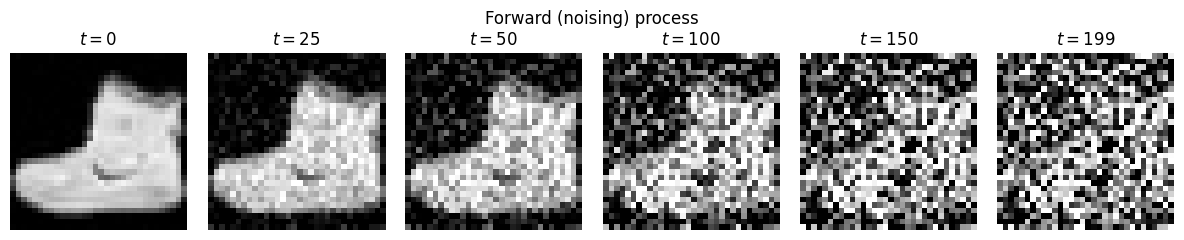

In [ ]:
# Sanity check: one image at increasing noise levels
x0 = diff_train[0][0].unsqueeze(0).to(device)
eps = torch.randn_like(x0)
ts = [0, 25, 50, 100, 150, 199]
fig, axes = plt.subplots(1, len(ts), figsize=(12, 2.4))
for ax, t in zip(axes, ts):
    ax.imshow(forward_sample(x0, torch.tensor([t], device=device), eps)[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"$t = {t}$")
    ax.axis("off")
plt.suptitle("Forward (noising) process")
plt.tight_layout()
plt.show()

### 2.2 Training (about 2 minutes per epoch on a T4 GPU)

In [ ]:
NUM_EPOCHS = 5

diff_model = Unet(dim=32, channels=1, dim_mults=(1, 2, 4)).to(device)
optimizer = optim.Adam(diff_model.parameters(), lr=1e-3)
print(f"U-Net parameters: {sum(p.numel() for p in diff_model.parameters()):,}")

for epoch in range(NUM_EPOCHS):
    diff_model.train()
    losses = []
    for X, _ in tqdm(diff_loader, leave=False, desc=f"epoch {epoch}"):
        x_0 = X.to(device)
        t = torch.randint(0, TOTAL_TIMESTEPS, (x_0.shape[0],), device=device)   # random timestep per image
        eps = torch.randn_like(x_0)
        loss = F.mse_loss(diff_model(forward_sample(x_0, t, eps), t), eps)       # predict the added noise
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    print(f"Epoch {epoch} | noise-prediction MSE: {np.mean(losses):.4f}")

U-Net parameters: 2,607,681


epoch 0:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 0 | noise-prediction MSE: 0.1503


epoch 1:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1 | noise-prediction MSE: 0.0785


epoch 2:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2 | noise-prediction MSE: 0.0683


epoch 3:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 3 | noise-prediction MSE: 0.0631


epoch 4:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 4 | noise-prediction MSE: 0.0600


### 2.3 Sampling

In [ ]:
@torch.no_grad()
def reverse_sample(model, x: torch.Tensor, t: torch.Tensor, i: int) -> torch.Tensor:
    # x_t -> x_{t-1}
    eps_pred = model(x, t)
    x0_pred = (x - torch.sqrt(1 - alpha_bar[i]) * eps_pred) / torch.sqrt(alpha_bar[i])
    x0_pred = x0_pred.clamp(-1, 1)   # keep the x_0 estimate in the data range

    a_bar_prev = alpha_bar[i - 1] if i > 0 else torch.ones_like(alpha_bar[i])
    beta_tilde = (1 - a_bar_prev) / (1 - alpha_bar[i]) * beta_t[i]
    mu_tilde = (torch.sqrt(alpha[i]) * (1 - a_bar_prev) / (1 - alpha_bar[i])) * x + (torch.sqrt(a_bar_prev) * beta_t[i] / (1 - alpha_bar[i])) * x0_pred
    return mu_tilde + torch.sqrt(beta_tilde) * torch.randn_like(x)   # beta_tilde = 0 at the last step


@torch.no_grad()
def sample(model, n: int = 1):
    # returns [x_T, x_{T-1}, ..., x_0], each a numpy array of shape (n, 1, H, W)
    model.eval()
    img = torch.randn(n, 1, IMG_SIZE, IMG_SIZE, device=device)
    traj = [img.cpu().numpy()]
    for i in reversed(range(TOTAL_TIMESTEPS)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        img = reverse_sample(model, img, t, i)
        traj.append(img.cpu().numpy())
    return traj

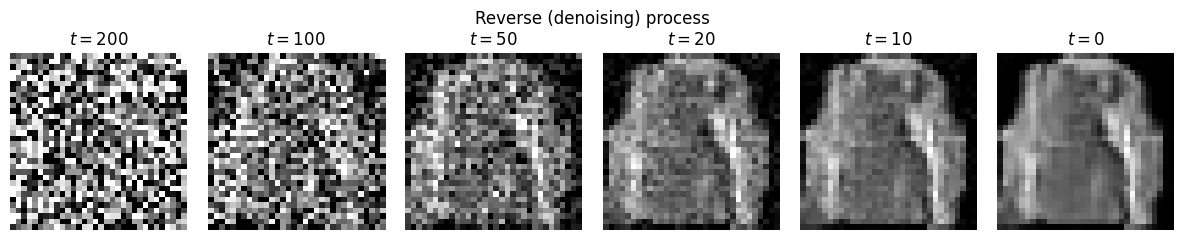

In [ ]:
# Denoising trajectory of one sample: traj[T - t] is x_t
traj = sample(diff_model, n=1)
timesteps = [200, 100, 50, 20, 10, 0]
fig, axes = plt.subplots(1, len(timesteps), figsize=(12, 2.4))
for ax, t in zip(axes, timesteps):
    ax.imshow(traj[TOTAL_TIMESTEPS - t][0, 0], cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"$t = {t}$")
    ax.axis("off")
plt.suptitle("Reverse (denoising) process")
plt.tight_layout()
plt.savefig("assets/diffusion_trajectory.png", dpi=150)
plt.show()

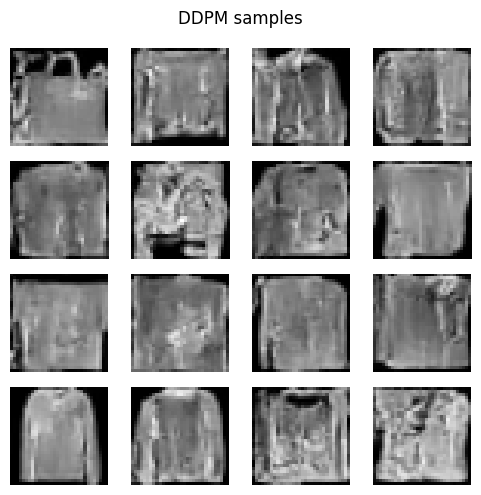

In [ ]:
# 16 independent samples
final = sample(diff_model, n=16)[-1]
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, img in zip(axes.flat, final):
    ax.imshow(img[0], cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
plt.suptitle("DDPM samples")
plt.tight_layout()
plt.savefig("assets/diffusion_samples.png", dpi=150)
plt.show()